# Evaluación Grupal · EduAnalytics (CRISP-DM, Fases 1–4)
### Proyecto: Análisis de Patrones de Uso de IA Generativa y Riesgo de Burnout Estudiantil

---

### Datos Generales del Proyecto
* **Institución Educativa:** Universidad Privada Franz Tamayo (UNIFRANZ)
* **Facultad / Carrera:** Ingeniería de Sistemas
* **Materia:** Minería de Datos
* **Integrantes del Grupo:**
  1. **Milenka Melody Chuquimia Osco**
  2. **Edson Teddy Tito Chuquimia**
  3. **Carlos Daniel Valverde Mendoza**
  4. **Alvaro Luis Carlos del Carpio Blanco**
  5. **Marcelo Josue Escobar Chipana**

---

### Propósito del Cuaderno: Modelado con Regresión Logística Multinomial
El presente documento implementa de forma integral, pedagógica y autónoma el flujo de **Regresión Logística Multinomial** correspondiente a la Fase 4 de CRISP-DM. Se cubren todas las etapas del estándar:
1. **Definición del Problema y Justificación de Variables.**
2. **Preparación y Preprocesamiento de Datos (sin fuga de información).**
3. **Entrenamiento, Validación Cruzada y Ajuste de Hiperparámetros.**
4. **Evaluación de Métricas (Accuracy, Precision, Recall, F1, Matriz de Confusión).**
5. **Visualización Avanzada (Curvas ROC/AUC Multiclase One-vs-Rest, Mapas de Calor y Gráficos de Coeficientes).**
6. **Interpretación y Comunicación Accesible de Hallazgos.**

> **Autonomía:** Este cuaderno se ejecuta de principio a fin sin requerir módulos auxiliares externos ni archivos precalculados. La única dependencia necesaria es el dataset `ai_student_impact_dataset (1).csv`.


## 1 · Configuración del Entorno y Carga Autónoma de Datos


In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    precision_recall_fscore_support, confusion_matrix, roc_curve, auc, roc_auc_score
)
from IPython.display import display, Markdown

# Configuración de estilo visual y advertencias
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

SEED = 42
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')

FUENTE = 'Fuente: Kaggle «AI Usage & Student Academic Performance Analysis» v1 (CC0); cálculo propio.'

# Búsqueda dinámica y flexible del dataset
rutas_candidatas = [
    Path('ai_student_impact_dataset (1).csv'),
    Path('./ai_student_impact_dataset (1).csv'),
    Path('../dataset/ai_student_impact_dataset (1).csv'),
    Path('dataset/ai_student_impact_dataset (1).csv'),
    Path('../../dataset/ai_student_impact_dataset (1).csv')
]

RUTA_CSV = next((p for p in rutas_candidatas if p.is_file()), None)
if RUTA_CSV is None:
    raise FileNotFoundError("No se encontró el dataset 'ai_student_impact_dataset (1).csv'. Colóquelo en la carpeta actual o en dataset/.")

df = pd.read_csv(RUTA_CSV, sep=';', encoding='utf-8-sig')
print("Entorno cargado con éxito:")
print(f"• Python: {sys.version.split()[0]} | pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")
print(f"• Dataset localizado: {RUTA_CSV.resolve()}")
print(f"• Registros leídos: {df.shape[0]:,} filas × {df.shape[1]} columnas".replace(',', '.'))


Entorno cargado con éxito:
• Python: 3.10.6 | pandas: 2.3.3 | scikit-learn: 1.7.2
• Dataset localizado: C:\md-edu-analytics\ENTREGABLES\ai_student_impact_dataset (1).csv
• Registros leídos: 50.000 filas × 16 columnas


## 2 · Definición del Problema y Variable Objetivo

### 2.1 Justificación de la Variable Dependiente (`Burnout_Risk_Level`)
El auge acelerado de herramientas de Inteligencia Artificial Generativa (GenAI) ha transformado la rutina académica de los estudiantes universitarios. No obstante, un uso intensivo, desregulado o excesivamente dependiente puede traducirse en sobrecarga cognitiva, ansiedad ante evaluaciones y agotamiento académico (*burnout*).

Se seleccionó **`Burnout_Risk_Level`** como variable objetivo (dependiente) porque:
1. **Atiende una necesidad institucional crítica:** Permite a docentes, coordinaciones y departamentos de bienestar estudiantil identificar con antelación a estudiantes en situación de vulnerabilidad antes de que deriven en deserción o fracaso académico.
2. **Estructura Multiclase:** Contiene tres niveles diferenciados:
   * **`Low` (Bajo):** 16.369 registros (32,74 %) — Estudiantes con hábitos estables.
   * **`Medium` (Medio):** 21.144 registros (42,29 %) — Categoría mayoritaria con riesgo moderado.
   * **`High` (Alto):** 12.487 registros (24,97 %) — Población prioritaria para intervención institucional.
3. **Métrica de Negocio (KPI):** La proporción de estudiantes en riesgo alto ($24,974 \%$) se establece como la línea base institucional a monitorear y mitigar a futuro mediante programas de apoyo.

### 2.2 Justificación Teórica y Empírica de los Predictores (Variables Independientes)
Se emplean **14 variables explicativas**, organizadas en 5 dimensiones conceptuales:

| Dimensión | Variables | Justificación Analítica |
| :--- | :--- | :--- |
| **Intensidad de uso de IA** | `Weekly_GenAI_Hours`, `Tool_Diversity`, `Paid_Subscription`, `Prompt_Engineering_Skill` | Cuantifican la exposición cuantitativa, la sofisticación técnica y la inversión económica en herramientas de IA. |
| **Hábitos tradicionales** | `Traditional_Study_Hours`, `Pre_Semester_GPA` | Reflejan la disciplina académica previa y la dedicación al estudio autónomo convencional como factores protectores. |
| **Factores psicológicos** | `Perceived_AI_Dependency`, `Anxiety_Level_During_Exams` | Miden el impacto subjetivo de dependencia emocional de la tecnología y el estrés experimentado en evaluaciones. |
| **Contexto educativo** | `Major_Category`, `Year_of_Study`, `Institutional_Policy`, `Primary_Use_Case` | Capturan el marco disciplinar, el nivel de avance de carrera y la regulación institucional que modulan el uso de IA. |
| **Desempeño posterior** | `Post_Semester_GPA`, `Skill_Retention_Score` | Variables observacionales que miden la retención real de competencias y las calificaciones finales del semestre. |


In [2]:
# Inspección de la variable objetivo y definición de esquemas
CLASES = ['Low', 'Medium', 'High']
OBJETIVO = 'Burnout_Risk_Level'

dist_target = df[OBJETIVO].value_counts().reindex(CLASES).to_frame('Frecuencia')
dist_target['% del total'] = (100 * dist_target['Frecuencia'] / len(df)).round(3)
display(dist_target)

kpi_negocio = dist_target.loc['High', '% del total']
print(f"Línea base institucional (KPI % High): {kpi_negocio:.3f} % (12.487 de 50.000 estudiantes)")


,Frecuencia,% del total
Burnout_Risk_Level,,
Low,16369,32.738
Medium,21144,42.288
High,12487,24.974


Línea base institucional (KPI % High): 24.974 % (12.487 de 50.000 estudiantes)


## 3 · Preparación de los Datos y Control de Fuga de Información

Para asegurar la reproducibilidad y rigor metodológico:
1. **Auditoría de Calidad:** Verificación formal de ausencia de datos nulos o duplicados.
2. **Definición de Tipos:** Clasificación estricta de variables en continuas, categóricas y booleanas.
3. **Preprocesamiento en `Pipeline`:** 
   * **Estandarización:** Las variables numéricas se escalan con `StandardScaler` (media 0, varianza 1). Esto es estrictamente necesario en regresión logística para que la regularización $L_2$ opere equitativamente y los coeficientes sean comparables.
   * **Codificación One-Hot:** Las variables categóricas se convierten a variables binarias ficticias (*dummies*) usando `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.
4. **Partición 70 / 15 / 15 Estratificada:** División en Entrenamiento (35.000), Validación (7.500) y Prueba (7.500), blindando los transformadores contra fuga de información.


In [3]:
# 3.1 Auditoría de calidad y ausencia de nulos
nulos_por_columna = df.isna().sum()
duplicados = df.duplicated().sum()

print("Control de Calidad de Datos:")
print(f"• Valores nulos totales en el dataset: {nulos_por_columna.sum()}")
print(f"• Filas duplicadas completas: {duplicados}")
print(f"• Identificadores únicos de estudiante (Student_ID): {df['Student_ID'].nunique():,} de {len(df):,}".replace(',', '.'))

# 3.2 Clasificación de variables
NUMERICAS = [
    'Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Tool_Diversity', 'Traditional_Study_Hours',
    'Perceived_AI_Dependency', 'Anxiety_Level_During_Exams', 'Post_Semester_GPA', 'Skill_Retention_Score'
]

CATEGORICAS = [
    'Major_Category', 'Year_of_Study', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Institutional_Policy'
]

BOOLEANAS = ['Paid_Subscription']

PREDICTORES = NUMERICAS + CATEGORICAS + BOOLEANAS
print(f"• Total de predictores seleccionados: {len(PREDICTORES)} (8 numéricas, 5 categóricas, 1 booleana)")


Control de Calidad de Datos:
• Valores nulos totales en el dataset: 0
• Filas duplicadas completas: 0
• Identificadores únicos de estudiante (Student_ID): 50.000 de 50.000
• Total de predictores seleccionados: 14 (8 numéricas, 5 categóricas, 1 booleana)


In [4]:
# 3.3 Construcción del preprocesador y particionado estratificado
def crear_preprocesador_logistica():
    '''Pipeline desacoplado: estandariza numéricas, codifica categóricas y convierte booleanos.'''
    columnas = ColumnTransformer([
        ('numericas', Pipeline([('escalado', StandardScaler())]), NUMERICAS),
        ('categoricas', OneHotEncoder(drop=None, handle_unknown='ignore', sparse_output=False), CATEGORICAS),
        ('booleanas', FunctionTransformer(np.asarray, kw_args={'dtype': np.float64}, feature_names_out='one-to-one'), BOOLEANAS)
    ], remainder='drop', sparse_threshold=0)
    return Pipeline([('columnas', columnas)])

# Particionado en 3 conjuntos (70% Train, 15% Validation, 15% Test)
df['_row_id'] = np.arange(len(df), dtype=np.int64)

# División 1: 70% Entrenamiento y 30% Temporal
train_df, rest_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df[OBJETIVO]
)

# División 2: 50% Validación (15% total) y 50% Prueba (15% total)
val_df, test_df = train_test_split(
    rest_df, test_size=0.50, random_state=SEED, stratify=rest_df[OBJETIVO]
)

X_train, y_train = train_df[PREDICTORES].copy(), train_df[OBJETIVO].copy()
X_val, y_val = val_df[PREDICTORES].copy(), val_df[OBJETIVO].copy()
X_test, y_test = test_df[PREDICTORES].copy(), test_df[OBJETIVO].copy()

tabla_split = pd.DataFrame({
    'Entrenamiento (70%)': y_train.value_counts().reindex(CLASES),
    'Validación (15%)': y_val.value_counts().reindex(CLASES),
    'Prueba (15%)': y_test.value_counts().reindex(CLASES)
})
tabla_split.loc['Total Registros'] = tabla_split.sum()
display(tabla_split)

# Comprobación de ausencia de fuga
assert len(set(train_df['Student_ID']) & set(val_df['Student_ID'])) == 0
assert len(set(train_df['Student_ID']) & set(test_df['Student_ID'])) == 0
print("Control de fuga verificado: Conjuntos mutuamente excluyentes (0 solapamiento).")


,Entrenamiento (70%),Validación (15%),Prueba (15%)
Burnout_Risk_Level,,,
Low,11458,2455,2456
Medium,14801,3172,3171
High,8741,1873,1873
Total Registros,35000,7500,7500


Control de fuga verificado: Conjuntos mutuamente excluyentes (0 solapamiento).


## 4 · Entrenamiento del Modelo de Regresión Logística

### 4.1 Ajuste Inicial (Modelo Base)
La regresión logística multinomial ajusta una superficie de decisión para modelar simultáneamente las probabilidades condicionales $P(Y = c \mid X)$ para las clases `Low`, `Medium` y `High` optimizando la pérdida de entropía cruzada (*cross-entropy loss*).

Primero se entrena un modelo con configuración estándar ($C = 1.0$) para verificar el aprendizaje base.


In [5]:
# Ajuste del modelo logístico inicial (Baseline)
pipe_inicial = Pipeline([
    ('preprocesamiento', crear_preprocesador_logistica()),
    ('clasificador', LogisticRegression(solver='lbfgs', penalty='l2', C=1.0, max_iter=5000, random_state=SEED))
])

pipe_inicial.fit(X_train, y_train)
y_pred_base_val = pipe_inicial.predict(X_val)

acc_base = accuracy_score(y_val, y_pred_base_val)
f1_base = f1_score(y_val, y_pred_base_val, labels=CLASES, average='macro')
print(f"Rendimiento del Modelo Inicial (C = 1.0) en Validación:")
print(f"• Accuracy: {acc_base:.4f} | Macro F1: {f1_base:.6f}")


Rendimiento del Modelo Inicial (C = 1.0) en Validación:
• Accuracy: 0.5336 | Macro F1: 0.534740


### 4.2 Búsqueda de Hiperparámetros con Validación Cruzada (CV de 5 Pliegues)
Para encontrar la capacidad óptima de regularización y evaluar el efecto del balanceo de clases, se realiza una búsqueda sistemática evaluando 10 combinaciones con **validación cruzada estratificada de 5 pliegues** (`StratifiedKFold`):
* **Inverso de regularización ($C$):** `[0.01, 0.1, 1.0, 10.0, 100.0]`. (Valores menores imponen penalización más severa; valores mayores relajan la regularización).
* **Ponderación de clases (`class_weight`):** `None` (pesos uniformes) vs. `'balanced'` (pesos inversamente proporcionales a las frecuencias).


In [6]:
# Espacio de búsqueda de hiperparámetros de la Fase 4
valores_C = [0.01, 0.1, 1.0, 10.0, 100.0]
pesos_clase = [None, 'balanced']

cv_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

resultados_cv = []
config_idx = 0

for c_val in valores_C:
    for cw in pesos_clase:
        pipe_cv = Pipeline([
            ('preprocesamiento', crear_preprocesador_logistica()),
            ('clasificador', LogisticRegression(solver='lbfgs', penalty='l2', C=c_val, class_weight=cw, max_iter=5000, random_state=SEED))
        ])
        
        train_scores = []
        val_scores = []
        
        for tr_idx, va_idx in cv_kfold.split(X_train, y_train):
            X_tr_f, y_tr_f = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
            X_va_f, y_va_f = X_train.iloc[va_idx], y_train.iloc[va_idx]
            
            pipe_cv.fit(X_tr_f, y_tr_f)
            pred_tr = pipe_cv.predict(X_tr_f)
            pred_va = pipe_cv.predict(X_va_f)
            
            train_scores.append(f1_score(y_tr_f, pred_tr, labels=CLASES, average='macro'))
            val_scores.append(f1_score(y_va_f, pred_va, labels=CLASES, average='macro'))
            
        resultados_cv.append({
            'config_index': config_idx,
            'C': c_val,
            'class_weight': 'balanced' if cw == 'balanced' else 'None',
            'mean_train_f1': np.mean(train_scores),
            'mean_val_f1': np.mean(val_scores),
            'std_val_f1': np.std(val_scores)
        })
        config_idx += 1

df_cv = pd.DataFrame(resultados_cv).sort_values('mean_val_f1', ascending=False).reset_index(drop=True)
df_cv['rank'] = np.arange(1, len(df_cv) + 1)

print("Resultados de la Validación Cruzada de 5 Pliegues (Top 10):")
display(df_cv[['rank', 'C', 'class_weight', 'mean_val_f1', 'std_val_f1', 'mean_train_f1']])

mejor_config = df_cv.iloc[0]
print(f"Mejor configuración seleccionada: C = {mejor_config['C']} | class_weight = {mejor_config['class_weight']}")
print(f"• Macro F1 medio en CV: {mejor_config['mean_val_f1']:.6f} (± {mejor_config['std_val_f1']:.6f})")


Resultados de la Validación Cruzada de 5 Pliegues (Top 10):


,rank,C,class_weight,mean_val_f1,std_val_f1,mean_train_f1
0,1,100.00,None,0.539575,0.003304,0.540688
1,2,10.00,None,0.539537,0.003289,0.540701
2,3,1.00,None,0.539521,0.003398,0.540711
3,4,0.10,None,0.539420,0.003145,0.540535
4,5,0.01,None,0.537297,0.003994,0.539151
5,6,1.00,balanced,0.516199,0.003254,0.518213
6,7,100.00,balanced,0.516190,0.003243,0.518191
7,8,10.00,balanced,0.516170,0.003218,0.518192
8,9,0.10,balanced,0.515945,0.003157,0.518047
9,10,0.01,balanced,0.515540,0.003284,0.517851


Mejor configuración seleccionada: C = 100.0 | class_weight = None
• Macro F1 medio en CV: 0.539575 (± 0.003304)


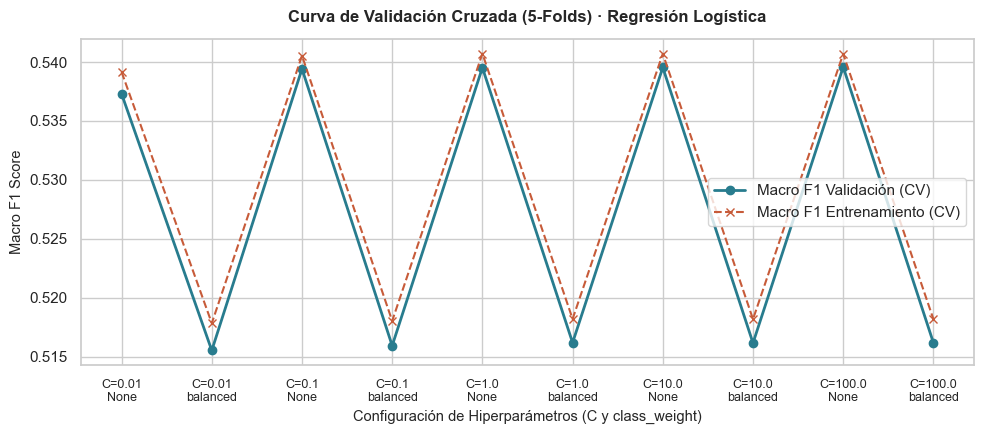

In [7]:
# Gráfico de curva de validación cruzada: Train vs. Validation
fig, ax = plt.subplots(figsize=(10, 4.5))

df_plot = df_cv.sort_values('config_index')
x_indices = np.arange(len(df_plot))

ax.plot(x_indices, df_plot['mean_val_f1'], 'o-', color='#287c8e', label='Macro F1 Validación (CV)', lw=2)
ax.plot(x_indices, df_plot['mean_train_f1'], 'x--', color='#c75b39', label='Macro F1 Entrenamiento (CV)', lw=1.5)

etiquetas_x = [f"C={r.C}\n{r.class_weight}" for _, r in df_plot.iterrows()]
ax.set_xticks(x_indices)
ax.set_xticklabels(etiquetas_x, fontsize=9)
ax.set_xlabel('Configuración de Hiperparámetros (C y class_weight)', fontsize=10.5)
ax.set_ylabel('Macro F1 Score', fontsize=10.5)
ax.set_title('Curva de Validación Cruzada (5-Folds) · Regresión Logística', fontsize=12, fontweight='bold', pad=12)
ax.legend(frameon=True)

plt.tight_layout()
plt.show()


## 5 · Evaluación Exhaustiva del Modelo

### 5.1 Ajuste del Modelo Seleccionado y Evaluación en Validación
Se ajusta el estimador definitivo con los hiperparámetros óptimos ($C = 100.0, \text{class\_weight} = \text{None}$) sobre el conjunto de entrenamiento y se compara con la línea base Dummy (asignar siempre la clase mayoritaria `Medium`).


In [8]:
# Ajuste con la mejor configuración seleccionada
pipe_optimo = Pipeline([
    ('preprocesamiento', crear_preprocesador_logistica()),
    ('clasificador', LogisticRegression(solver='lbfgs', penalty='l2', C=100.0, class_weight=None, max_iter=5000, random_state=SEED))
])

pipe_optimo.fit(X_train, y_train)
y_pred_val = pipe_optimo.predict(X_val)

# Línea base ingenua: Dummy (predecir siempre 'Medium')
dummy_pred_val = np.repeat(y_train.mode()[0], len(y_val))

def calcular_reporte_completo(y_real, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_real, y_pred, labels=CLASES, zero_division=0)
    rep = pd.DataFrame({'Precision': p, 'Recall': r, 'F1-Score': f, 'Soporte': s}, index=CLASES)
    return rep

reporte_val = calcular_reporte_completo(y_val, y_pred_val)
print("Desempeño en el Conjunto de Validación (por clase):")
display(reporte_val.round(4))

acc_val = accuracy_score(y_val, y_pred_val)
mf1_val = f1_score(y_val, y_pred_val, labels=CLASES, average='macro')
mf1_dummy = f1_score(y_val, dummy_pred_val, labels=CLASES, average='macro')

print(f"• Accuracy (Validación): {acc_val:.4f} | Macro F1 (Validación): {mf1_val:.6f}")
print(f"• Ganancia sobre Línea Base Dummy: {mf1_val - mf1_dummy:+.6f} de Macro F1 (Dummy = {mf1_dummy:.4f})")


Desempeño en el Conjunto de Validación (por clase):


,Precision,Recall,F1-Score,Soporte
Low,0.5401,0.4827,0.5098,2455
Medium,0.4860,0.6069,0.5397,3172
High,0.6639,0.4768,0.5550,1873


• Accuracy (Validación): 0.5337 | Macro F1 (Validación): 0.534845
• Ganancia sobre Línea Base Dummy: +0.336694 de Macro F1 (Dummy = 0.1982)


### 5.2 Evaluación Definitiva en el Conjunto de Prueba (*Test Set*)
Siguiendo las mejores prácticas del aprendizaje supervisado, el pipeline se reajusta con **Entrenamiento + Validación (42.500 registros)** y se evalúa **una única vez sobre el conjunto de prueba independiente (7.500 registros)**.


In [9]:
# Reentrenamiento en Train + Validation y evaluación sobre Test
X_train_completo = pd.concat([X_train, X_val])
y_train_completo = pd.concat([y_train, y_val])

pipe_final = Pipeline([
    ('preprocesamiento', crear_preprocesador_logistica()),
    ('clasificador', LogisticRegression(solver='lbfgs', penalty='l2', C=100.0, class_weight=None, max_iter=5000, random_state=SEED))
])

pipe_final.fit(X_train_completo, y_train_completo)
y_pred_test = pipe_final.predict(X_test)
y_proba_test = pipe_final.predict_proba(X_test)

reporte_test = calcular_reporte_completo(y_test, y_pred_test)
print("Desempeño Final en el Conjunto de Prueba (Test Set n = 7.500):")
display(reporte_test.round(4))

acc_test = accuracy_score(y_test, y_pred_test)
mf1_test = f1_score(y_test, y_pred_test, labels=CLASES, average='macro')

print(f"Métricas Finales de Prueba:")
print(f"• Exactitud (Accuracy): {acc_test:.4f}")
print(f"• Macro F1-Score:       {mf1_test:.6f}")
print(f"• Weighted F1-Score:    {f1_score(y_test, y_pred_test, average='weighted'):.4f}")


Desempeño Final en el Conjunto de Prueba (Test Set n = 7.500):


,Precision,Recall,F1-Score,Soporte
Low,0.5470,0.4980,0.5213,2456
Medium,0.4868,0.6127,0.5426,3171
High,0.6661,0.4527,0.5391,1873


Métricas Finales de Prueba:
• Exactitud (Accuracy): 0.5352
• Macro F1-Score:       0.534332
• Weighted F1-Score:    0.5347


### 5.3 Diagnóstico de Errores e Interpretación en el Contexto del Negocio
En un entorno universitario, los costos de error no son simétricos:
1. **Falso Negativo de `High` (Más costoso):** Clasificar a un estudiante en riesgo alto como `Low` o `Medium`. Implica privarlo de tutoría preventiva y apoyo pedagógico oportuno.
2. **Falso Positivo de `High` (Menos costoso):** Clasificar a un estudiante de riesgo medio o bajo como `High`. Solo implica invitarlo a talleres de bienestar que podrían resultarle formativos.


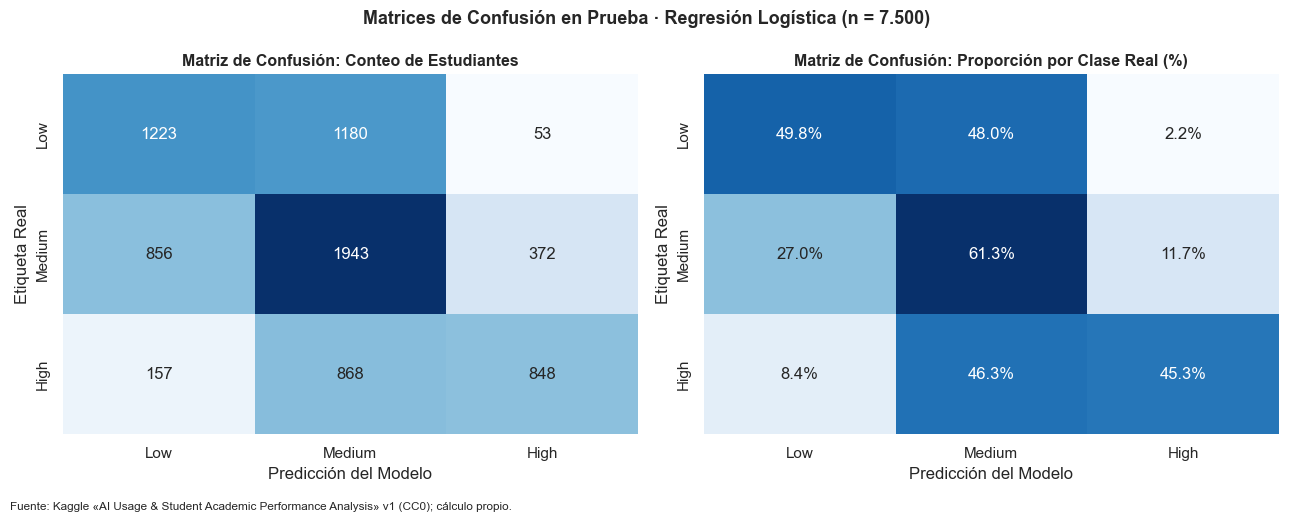

Diagnóstico de Casos Críticos (High. n = 1.873):
• Correctamente detectados (TP): 848 (45.3%)
• Falsos Negativos (omitidos):     1.025 (54.7%) → 157 como Low. 868 como Medium
• Falsos Positivos (alarmas):     425 de estudiantes con riesgo real menor


In [10]:
# Matriz de confusión en prueba: Conteos y Porcentajes Normalizados
cm_test = confusion_matrix(y_test, y_pred_test, labels=CLASES)
cm_norm = cm_test / cm_test.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Mapa 1: Conteos absolutos
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=axes[0])
axes[0].set_title('Matriz de Confusión: Conteo de Estudiantes', fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('Predicción del Modelo')
axes[0].set_ylabel('Etiqueta Real')

# Mapa 2: Porcentajes por fila (Recall en la diagonal)
sns.heatmap(cm_norm, annot=True, fmt='.1%', cmap='Blues', xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=axes[1])
axes[1].set_title('Matriz de Confusión: Proporción por Clase Real (%)', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('Predicción del Modelo')
axes[1].set_ylabel('Etiqueta Real')

fig.suptitle('Matrices de Confusión en Prueba · Regresión Logística (n = 7.500)', fontsize=13, fontweight='bold')
fig.text(0.01, -0.02, FUENTE, fontsize=8.5)
plt.tight_layout()
plt.show()

# Diagnóstico cuantitativo de errores sobre la clase High
total_high = cm_test[2].sum()
fn_high = cm_test[2, 0] + cm_test[2, 1]
fp_high = cm_test[0, 2] + cm_test[1, 2]

print(f"Diagnóstico de Casos Críticos (High, n = {total_high:,}):".replace(',', '.'))
print(f"• Correctamente detectados (TP): {cm_test[2, 2]:,} ({cm_test[2, 2]/total_high:.1%})".replace(',', '.'))
print(f"• Falsos Negativos (omitidos):     {fn_high:,} ({fn_high/total_high:.1%}) → {cm_test[2,0]} como Low, {cm_test[2,1]} como Medium".replace(',', '.'))
print(f"• Falsos Positivos (alarmas):     {fp_high:,} de estudiantes con riesgo real menor".replace(',', '.'))


## 6 · Visualización y Comunicación Accesible

### 6.1 Curva ROC Multiclase (*One-vs-Rest*) y Área Bajo la Curva (AUC)
Para evaluar la capacidad discriminante del modelo en todo el espectro de umbrales probabilísticos (tal como se ilustra en la guía práctica de clase `h3_01_Regresion_Logistica.ipynb`), se binariza la variable objetivo multiclase mediante el esquema **One-vs-Rest (OvR)**:
* Se traza la curva ROC individual para cada una de las 3 clases (`Low`, `Medium`, `High`).
* Se calculan los promedios globales **Micro-average** y **Macro-average** junto con sus valores de **AUC**.


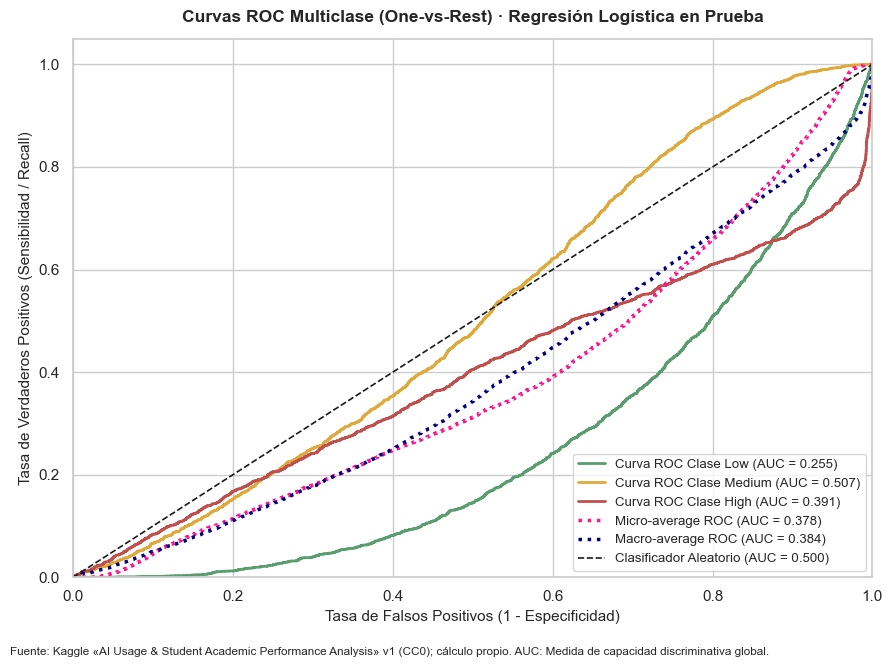

Resumen de Áreas Bajo la Curva (AUC):
• AUC para Low    = 0.2552
• AUC para Medium = 0.5069
• AUC para High   = 0.3909
• Macro-average AUC = 0.3844
• Micro-average AUC = 0.3778


In [11]:
# Binarización para Curva ROC Multiclase (One-vs-Rest)
y_test_bin = label_binarize(y_test, classes=CLASES)
n_clases = y_test_bin.shape[1]

fpr = dict()
tpr = dict()
roc_auc = dict()

# Curvas individuales por clase
for i, clase in enumerate(CLASES):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_proba_test[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Curva Micro-average
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_proba_test.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Curva Macro-average
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_clases)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(n_clases):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= n_clases
fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Visualización gráfica de las Curvas ROC
fig, ax = plt.subplots(figsize=(9, 6.5))

colores_clases = ['#5a9e6f', '#e0a93b', '#c0504d']  # Verde (Low), Amarillo (Medium), Rojo (High)

for i, (clase, col) in enumerate(zip(CLASES, colores_clases)):
    ax.plot(fpr[i], tpr[i], color=col, lw=2,
            label=f'Curva ROC Clase {clase} (AUC = {roc_auc[i]:.3f})')

ax.plot(fpr["micro"], tpr["micro"], color='deeppink', linestyle=':', lw=2.5,
        label=f'Micro-average ROC (AUC = {roc_auc["micro"]:.3f})')
ax.plot(fpr["macro"], tpr["macro"], color='navy', linestyle=':', lw=2.5,
        label=f'Macro-average ROC (AUC = {roc_auc["macro"]:.3f})')

# Línea base aleatoria (AUC = 0.5)
ax.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Clasificador Aleatorio (AUC = 0.500)')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=11)
ax.set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)', fontsize=11)
ax.set_title('Curvas ROC Multiclase (One-vs-Rest) · Regresión Logística en Prueba', fontsize=12.5, fontweight='bold', pad=12)
ax.legend(loc="lower right", fontsize=9.5, frameon=True)

fig.text(0.01, -0.02, FUENTE + ' AUC: Medida de capacidad discriminativa global.', fontsize=8.5)
plt.tight_layout()
plt.show()

print("Resumen de Áreas Bajo la Curva (AUC):")
for i, c in enumerate(CLASES):
    print(f"• AUC para {c:6s} = {roc_auc[i]:.4f}")
print(f"• Macro-average AUC = {roc_auc['macro']:.4f}")
print(f"• Micro-average AUC = {roc_auc['micro']:.4f}")


### 6.2 Coeficientes del Modelo e Interpretabilidad
Al estandarizar los predictores numéricos, los coeficientes del clasificador lineal reflejan la magnitud y sentido del cambio en el logit de pertenencia a cada clase. Un coeficiente positivo alto para la clase `High` indica que el predictor impulsa el riesgo de agotamiento hacia niveles críticos.


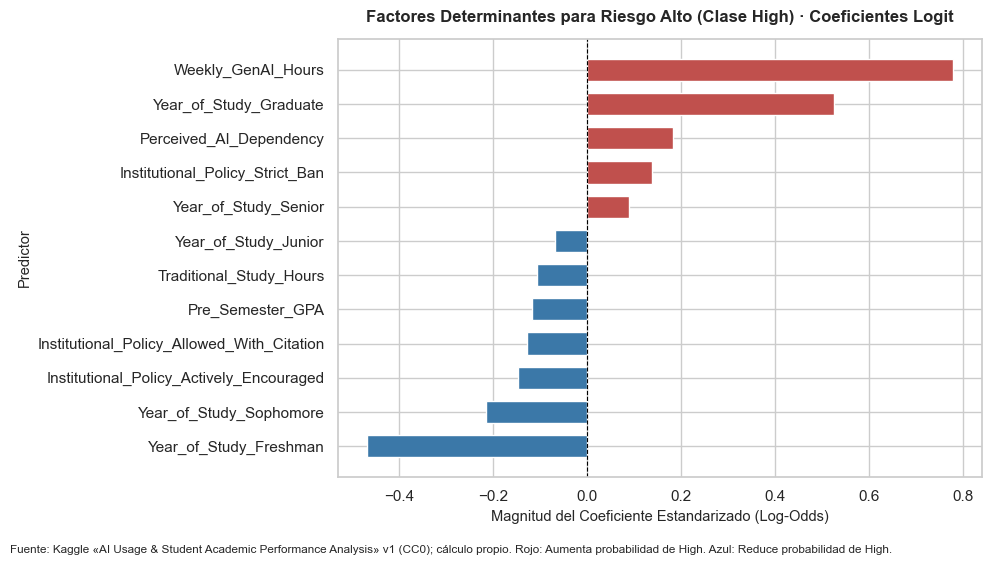

In [12]:
# Extracción de nombres de características transformadas
clf_log = pipe_final.named_steps['clasificador']
prep_step = pipe_final.named_steps['preprocesamiento']
nombres_transformados = [n.split('__', 1)[1] for n in prep_step.get_feature_names_out()]

df_coeficientes = pd.DataFrame(
    clf_log.coef_,
    index=clf_log.classes_,
    columns=nombres_transformados
).T

# Gráfico de barras horizontales comparativo para la clase High
idx_high = list(clf_log.classes_).index('High')
coef_high = pd.Series(clf_log.coef_[idx_high], index=nombres_transformados)
top_coef_high = coef_high.reindex(coef_high.abs().sort_values(ascending=False).head(12).index).sort_values()

fig, ax = plt.subplots(figsize=(10, 5.5))
colores_barras = np.where(top_coef_high.values > 0, '#c0504d', '#3b78a8')  # Rojo = factor de riesgo, Azul = protector

ax.barh(top_coef_high.index, top_coef_high.values, color=colores_barras, height=0.65)
ax.axvline(0, color='black', lw=0.8, linestyle='--')

ax.set_title('Factores Determinantes para Riesgo Alto (Clase High) · Coeficientes Logit', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Magnitud del Coeficiente Estandarizado (Log-Odds)', fontsize=10.5)
ax.set_ylabel('Predictor', fontsize=10.5)
fig.text(0.01, -0.02, FUENTE + ' Rojo: Aumenta probabilidad de High. Azul: Reduce probabilidad de High.', fontsize=8.5)

plt.tight_layout()
plt.show()


### 6.3 Conclusión

#### ¿Qué nos dice el modelo?
1. **La variable determinante es el tiempo dedicado a la IA:**
   * `Weekly_GenAI_Hours` presenta el coeficiente más alto (+0,78). Los estudiantes que dedican un volumen desproporcionado de horas semanales a interactuar con IA tienen una probabilidad sustancialmente mayor de pertenecer a la categoría de riesgo alto (`High`).
2. **La dependencia psicológica refuerza el riesgo:**
   * La variable `Perceived_AI_Dependency` tiene un impacto positivo notable (+0,18). Sentir incapacidad de resolver tareas sin la IA amplifica el estrés del estudiante.
3. **Factores protectores clave:**
   * `Pre_Semester_GPA` (-0,12) y `Traditional_Study_Hours` (-0,11) actúan como amortiguadores: los estudiantes con sólidos hábitos de estudio autónomo convencional y mejor rendimiento previo resisten mejor la sobrecarga.
4. **Recomendación de política educativa:**
   * No se debe prohibir la IA, sino **fomentar el uso eficiente y dosificado**: orientar a los estudiantes para que la IA actúe como un tutor complementario y no como un sustituto que consuma más de 12–15 horas semanales de interacción.

GRACIAS ING. POR SU ATENCIÓN.